In [1]:
!pip install -q datasets

# **Xây dựng một hệ thống phân loại cảm xúc bằng hình ảnh dựa theo Mạng học sâu**

In [2]:
from datasets import load_dataset

# Load dataset
ds = load_dataset("abhilash88/fer2013-enhanced")
print(ds)

README.md:   0%|          | 0.00/10.8k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  171MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 36.6MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 36.8MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25117 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5380 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5390 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 25117
    })
    validation: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 5380
    })
    test: Dataset({
        features: ['sample_id', 'image', 'emotion', 'emotion_name', 'pixels', 'usage', 'quality_score', 'brightness', 'contrast', 'sample_weight', 'pixel_mean', 'pixel_std', 'pixel_min', 'pixel_max', 'edge_score', 'focus_score', 'brightness_score'],
        num_rows: 5390
    })
})


## **1. Setup Env & Understanding Data**

In [51]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

# Kiểm tra GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [15]:
print(ds["train"].features)
sample = ds["train"][0]
print({k: (v if not isinstance(v, (list, dict)) else type(v)) for k, v in sample.items()})

{'sample_id': Value('string'), 'image': Array2D(shape=(48, 48), dtype='uint8'), 'emotion': ClassLabel(names=['angry', 'disgust', 'fear', 'happy', 'sad', 'surprise', 'neutral']), 'emotion_name': Value('string'), 'pixels': Value('string'), 'usage': Value('string'), 'quality_score': Value('float32'), 'brightness': Value('float32'), 'contrast': Value('float32'), 'sample_weight': Value('float32'), 'pixel_mean': Value('float32'), 'pixel_std': Value('float32'), 'pixel_min': Value('uint8'), 'pixel_max': Value('uint8'), 'edge_score': Value('float32'), 'focus_score': Value('float32'), 'brightness_score': Value('float32')}
{'sample_id': 'fer2013_006289', 'image': <class 'list'>, 'emotion': 6, 'emotion_name': 'neutral', 'pixels': '91 99 49 0 3 0 2 2 9 50 97 131 144 143 148 155 160 168 173 177 182 189 195 201 203 203 200 204 205 204 204 203 195 188 182 177 169 161 157 154 150 138 125 95 83 46 5 18 91 99 48 0 3 1 1 11 53 101 129 141 139 143 151 157 160 169 175 179 188 193 196 199 201 200 202 205 205

Cảm xúc: neutral
Điểm chất lượng (Quality Score): 0.42


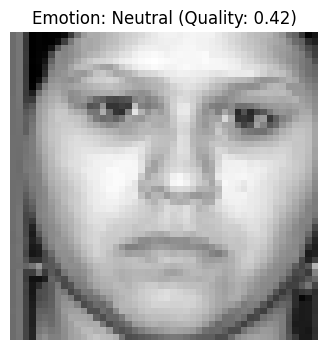

In [22]:
image = sample["image"]           # Đối tượng PIL.Image
emotion = sample["emotion_name"]    # Tên cảm xúc (VD: Happy, Sad, Neutral...)
quality = sample["quality_score"]

print(f"Cảm xúc: {emotion}")
print(f"Điểm chất lượng (Quality Score): {quality:.2f}")

# 3. Hiển thị ảnh đơn lẻ
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title(f"Emotion: {emotion.capitalize()} (Quality: {quality:.2f})")
plt.axis("off")
plt.show()

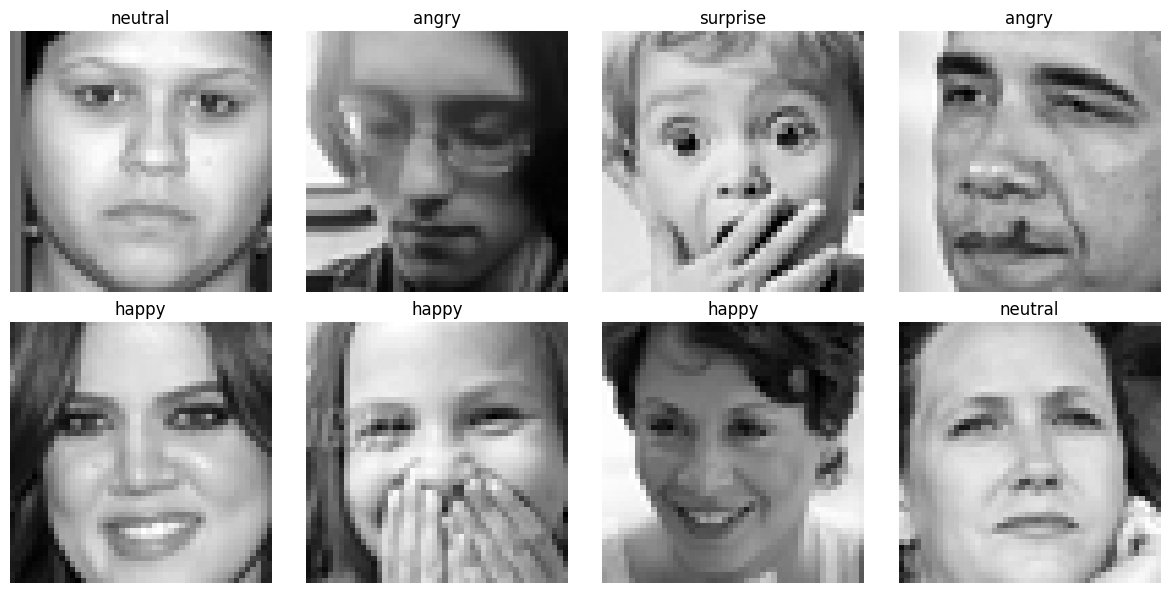

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes = axes.flatten()

for i, ax in enumerate(axes):
    sample = ds["train"][i]
    image = sample["image"]
    emotion = sample["emotion_name"]

    ax.imshow(image, cmap="gray")
    ax.set_title(f"{emotion}")
    ax.axis("off")

plt.tight_layout()
plt.show()

**Nhận xét**

- Data bao gồm 35887 mẫu với mỗi mẫu bao gồm 3 đặc trưng
- Các đặc trưng bao gồm:
  - `emotion:` Được đánh số từ 9 -> 7 biểu thị cho 7 nhãn cảm xúc
  - `pixels:` Là các pixel của ảnh để mô hình có thể học được các đặc trưng
  - `Usage:` Đặc trưng này dùng để tách tập dữ liệu lớn thành các tập nhỏ vơi mục tiêu train, valid, test
- Target: nhãn mục tiêu lựa chọn là emotion

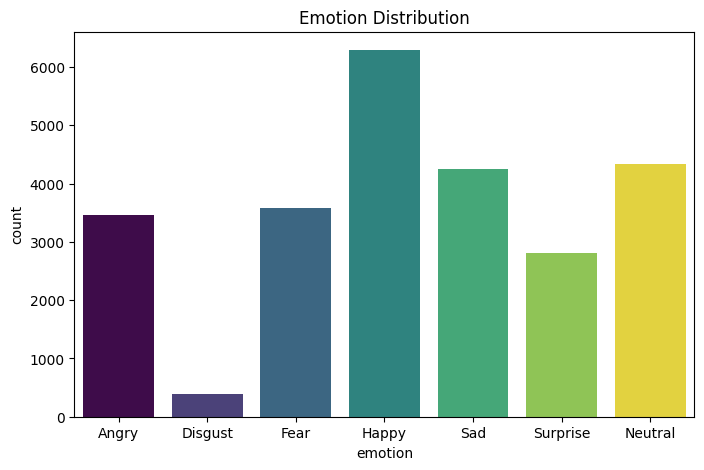

In [28]:
# Chuyển tập dữ liệu Hugging Face sang Pandas DataFrame để sử dụng biến `df`
train = pd.DataFrame(ds["train"])

emotion_labels = [
    "Angry", "Disgust", "Fear",
    "Happy", "Sad", "Surprise", "Neutral"
]

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train,
    x="emotion",
    hue="emotion",
    palette="viridis",
    legend=False
)

plt.xticks(range(7), emotion_labels)
plt.title("Emotion Distribution")
plt.show()

**Nhận xét**

Phân bố nhóm Happy là nhiều nhất thấp nhất là mắc cỡ

## **2. Xây dựng DataLoader**

In [29]:
class FER2013Dataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe
        self.transform = transform

        self.images = [
            np.fromstring(pixel, dtype=np.uint8, sep=' ')
            .reshape(48, 48)
            for pixel in dataframe["pixels"]
        ]

        self.labels = dataframe["emotion"].values

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = int(self.labels[idx])

        # Chuyển numpy sang PIL
        from PIL import Image
        image = Image.fromarray(image, mode="L")

        if self.transform:
            image = self.transform(image)

        return image, label

In [30]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1),
        scale=(0.9, 1.1)
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

In [32]:
train_df = pd.DataFrame(ds["train"])
val_df = pd.DataFrame(ds["validation"])
test_df = pd.DataFrame(ds["test"])

train_dataset = FER2013Dataset(train_df, train_transform)
val_dataset = FER2013Dataset(val_df, val_transform)
test_dataset = FER2013Dataset(test_df, val_transform)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

## **3. Xây dựng Mô hình**

In [33]:
# ==========================================
# 1. SmallCNN (1 Block Convolution)
# ==========================================
class SmallCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(SmallCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        # Giả sử ảnh 48x48 -> qua 1 MaxPool2d còn 24x24
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 24 * 24, 256),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(256),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### **MediumCNN**

In [34]:

# ==========================================
# 2. MediumCNN (2 Blocks Convolution)
# ==========================================
class MediumCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(MediumCNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            # Block 2
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.25)
        )
        # Ảnh 48x48 -> qua 2 MaxPool2d còn 12x12
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 12 * 12, 256),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(256),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### **Medium01CNN**

In [35]:
# ==========================================
# 3. Medium01CNN (3 Blocks Convolution)
# ==========================================
class Medium01CNN(nn.Module):
    def __init__(self, num_classes=7):
        super(Medium01CNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            # Block 2
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            # Block 3
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.3)
        )
        # Ảnh 48x48 -> qua 3 MaxPool2d còn 6x6
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 6 * 6, 256),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(256),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

### **LargeCNN**

In [36]:
# ==========================================
# 4. LargeCNN (4 Blocks Convolution - Mô hình gốc)
# ==========================================
class LargeCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(LargeCNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 64, kernel_size=3, padding=1), # Dùng kernel để lọc các đặc trưng ảnh
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True), # Hàm kích hoạt học các phi tuyến
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # Lấy giá trị lớn nhất sau khi đã dùng kernel lọc xong
            nn.Dropout(0.25), # Gỉam overfitting bằng cách tắt ngẫu nhiên

            # Block 2
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.25),

            # Block 3
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),

            # Block 4
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout(0.3)
        )
        # Ảnh 48x48 -> qua 4 MaxPool2d còn 3x3
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 3 * 3, 256),
            nn.ReLU(inplace=True),
            nn.BatchNorm1d(256),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

# **4. Training và Đánh giá**

In [38]:
criterion = nn.CrossEntropyLoss() # Hàm loss

optimizer = optim.Adam(
    model.parameters(), # Tối ưu bằng Adam
    lr=0.001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=4
)

In [39]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()

    running_loss = 0
    correct = 0
    total = 0

    progress_bar = tqdm(loader, desc="Training")

    for images, labels in progress_bar:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix(
            loss=loss.item(),
            acc=100 * correct / total
        )

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [40]:
def validate(model, loader, criterion):
    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / total
    val_acc = correct / total

    return val_loss, val_acc

## **Training**

In [48]:
models = { "SmallCNN" : SmallCNN().to(device),
          "MediumCNN" : MediumCNN().to(device),
          "Medium01CNN" : Medium01CNN().to(device),
          "LargeCNN" : LargeCNN().to(device),
          }

In [52]:
epochs = 2
patience = 10

# Cấu trúc lại history thành dictionary lồng nhau để quản lý theo từng model
history = {}

for name, model in models.items():
    print(f"\n{'='*25} Đang train model: {name} {'='*25}")
    # 2. Khởi tạo lại trạng thái Early Stopping & Best Accuracy cho từng model
    best_val_acc = 0.0
    counter = 0

    # Tạo cấu trúc lưu history riêng biệt cho model này
    history[name] = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    for epoch in range(epochs):
        print(f"\nEpoch [{epoch+1}/{epochs}]")

        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_loss, val_acc = validate(
            model,
            val_loader,
            criterion
        )

        # Scheduler cập nhật dựa trên val_loss của model hiện tại
        scheduler.step(val_loss)

        # Lưu metrics vào history của model tương ứng
        history[name]["train_loss"].append(train_loss)
        history[name]["train_acc"].append(train_acc)
        history[name]["val_loss"].append(val_loss)
        history[name]["val_acc"].append(val_acc)

        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%")
        print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")

        # Kiểm tra và lưu best model riêng biệt
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            counter = 0

            # Lưu file riêng theo tên model để tránh bị ghi đè
            torch.save(
                model.state_dict(),
                f"{name}_best_model.pth"
            )

            print(f"-> Saved best model for {name}!")

        else:
            counter += 1

        if counter >= patience:
            print(f"-> Early stopping triggered for {name}!")
            break

    print(f"==> Hoàn tất {name}. Best Validation Accuracy: {best_val_acc * 100:.2f}%\n")


========================= Đang train model: SmallCNN =========================

Epoch [1/2]


Training:   0%|          | 0/393 [00:00<?, ?it/s]

Train Loss: 2.0879 | Train Acc: 13.78%
Val Loss: 2.0038 | Val Acc: 15.91%
-> Saved best model for SmallCNN!

Epoch [2/2]


Training:   0%|          | 0/393 [00:00<?, ?it/s]

Train Loss: 2.0922 | Train Acc: 13.94%
Val Loss: 2.0030 | Val Acc: 15.97%
-> Saved best model for SmallCNN!
==> Hoàn tất SmallCNN. Best Validation Accuracy: 15.97%


========================= Đang train model: MediumCNN =========================

Epoch [1/2]


Training:   0%|          | 0/393 [00:00<?, ?it/s]

... (9 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d389ba44180>Exception ignored in: 
Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7d389ba44180>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__

Traceback (most recent call last):
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
        self._shutdown_workers()if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
assert self._parent_pid == os.getpid(), 'can only test a child process'    
AssertionErrorif w.is_alive():: can only test a child process

  File "/usr/lib/

Train Loss: 2.0092 | Train Acc: 15.13%
Val Loss: 1.9478 | Val Acc: 16.90%
-> Saved best model for LargeCNN!

Epoch [2/2]


Training:   0%|          | 0/393 [00:00<?, ?it/s]

Train Loss: 2.0114 | Train Acc: 15.52%
Val Loss: 1.9535 | Val Acc: 16.90%
==> Hoàn tất LargeCNN. Best Validation Accuracy: 16.90%



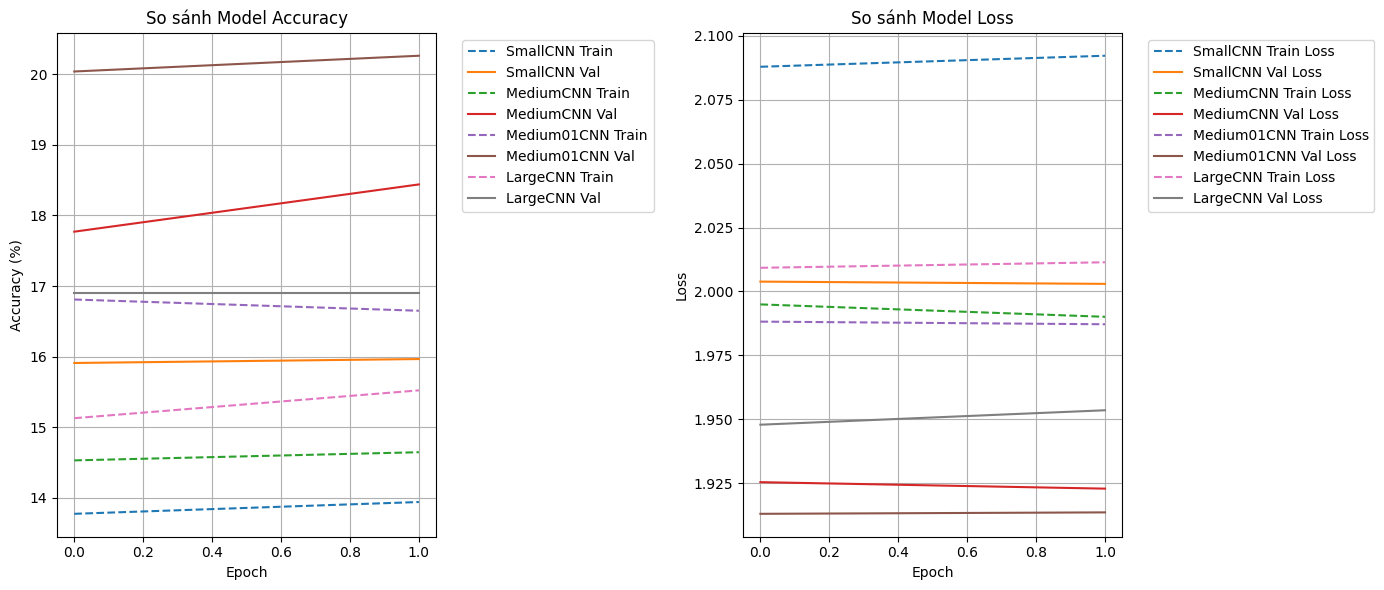

In [53]:
# 1. Vẽ biểu đồ Accuracy cho tất cả các model
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
for name, metrics in history.items():
    # Nếu accuracy của bạn lưu dưới dạng số thực (ví dụ: 0.85), nhân 100 để hiển thị dạng %
    train_acc = [acc * 100 for acc in metrics["train_acc"]]
    val_acc = [acc * 100 for acc in metrics["val_acc"]]

    plt.plot(train_acc, linestyle='--', label=f"{name} Train")
    plt.plot(val_acc, linestyle='-', label=f"{name} Val")

plt.title("So sánh Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)

# 2. Vẽ biểu đồ Loss cho tất cả các model
plt.subplot(1, 2, 2)
for name, metrics in history.items():
    plt.plot(metrics["train_loss"], linestyle='--', label=f"{name} Train Loss")
    plt.plot(metrics["val_loss"], linestyle='-', label=f"{name} Val Loss")

plt.title("So sánh Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True)

plt.tight_layout()
plt.show()

## **4. Đánh giá và thử nghiệm**

In [55]:
# Chọn mô hình cần đánh giá (ví dụ: LargeCNN)
evaluated_model_name = "LargeCNN"
evaluated_model = models[evaluated_model_name]

# Load đúng file checkpoint tương ứng đã lưu trong quá trình train
evaluated_model.load_state_dict(
    torch.load(
        f"{evaluated_model_name}_best_model.pth",
        map_location=device,
        weights_only=True
    )
)

evaluated_model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc=f"Evaluating {evaluated_model_name}"):
        images = images.to(device)
        outputs = evaluated_model(images)
        predictions = torch.argmax(outputs, dim=1)
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# In kết quả Classification Report
print(classification_report(
    all_labels,
    all_predictions,
    target_names=emotion_labels
))

Evaluating LargeCNN:   0%|          | 0/85 [00:00<?, ?it/s]

              precision    recall  f1-score   support

       Angry       0.00      0.00      0.00       744
     Disgust       0.00      0.00      0.00        83
        Fear       0.17      0.00      0.00       769
       Happy       0.00      0.00      0.00      1349
         Sad       0.17      0.99      0.29       913
    Surprise       0.14      0.00      0.01       601
     Neutral       0.00      0.00      0.00       931

    accuracy                           0.17      5390
   macro avg       0.07      0.14      0.04      5390
weighted avg       0.07      0.17      0.05      5390



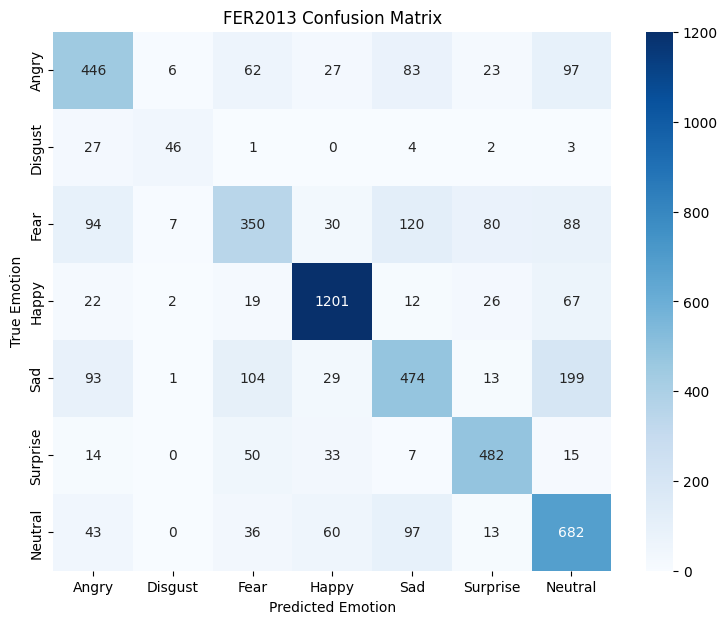

In [44]:
cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotion_labels,
    yticklabels=emotion_labels
)

plt.xlabel("Predicted Emotion")
plt.ylabel("True Emotion")
plt.title("FER2013 Confusion Matrix")

plt.show()

/tmp/ipykernel_930/2151616165.py:23: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  image = Image.fromarray(image, mode="L")


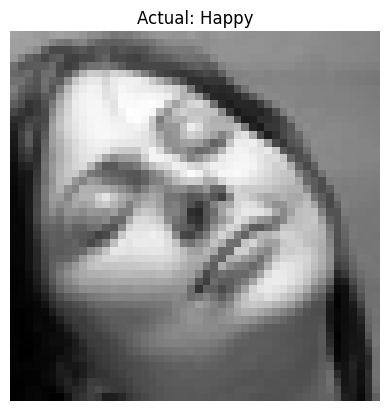

Emotion: Happy
Confidence: 57.76%


('Happy',
 array([[0.05690768, 0.00373394, 0.04746949, 0.5775582 , 0.05263798,
         0.00192478, 0.25976792]], dtype=float32))

In [45]:
def predict_emotion(image, model):
    model.eval()

    if isinstance(image, np.ndarray):
        from PIL import Image
        image = Image.fromarray(image.astype(np.uint8))

    transform = transforms.Compose([
        transforms.Grayscale(num_output_channels=1),
        transforms.Resize((48, 48)),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])
    ])

    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image)

        probabilities = torch.softmax(output, dim=1)

        confidence, predicted = torch.max(probabilities, 1)

    emotion = emotion_labels[predicted.item()]

    print("Emotion:", emotion)
    print(f"Confidence: {confidence.item()*100:.2f}%")

    return emotion, probabilities.cpu().numpy()


# Thử nghiệm với một ảnh trong tập test
image, label = test_dataset[10]

plt.imshow(image.squeeze().numpy(), cmap="gray")
plt.title("Actual: " + emotion_labels[label])
plt.axis("off")
plt.show()

# Lưu ý: image đang là tensor đã chuẩn hóa,
# hàm dự đoán nhận ảnh PIL hoặc numpy uint8.
sample_image = test_dataset.images[10]

predict_emotion(sample_image, model)